# Lecture 15: Class demo

Let's cluster images!!

![](img/eva-fun-times.png)

For this demo, I'm going to use the following image dataset: 
1. A tiny subset of [Food-101](https://www.kaggle.com/datasets/kmader/food41?select=food_c101_n10099_r32x32x1.h5) from last lecture
(available [here](https://github.ubc.ca/mds-2021-22/datasets/blob/master/data/food.zip)).
2. A small subset of [Human Faces dataset](https://www.kaggle.com/datasets/ashwingupta3012/human-faces) (available [here](https://ubcca-my.sharepoint.com/:u:/g/personal/varada_kolhatkar_ubc_ca/EYDqm7QJLfdGh1A0dyqh76kB6PH9ohca-lVrJGATrEh3CQ?e=msqcPM)).

To run the code below, you need to install pytorch and torchvision in the course conda environment. 

```conda install pytorch torchvision -c pytorch```

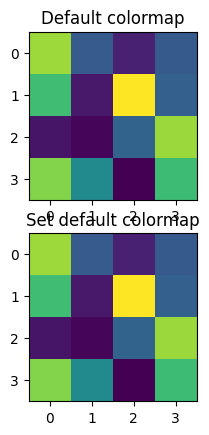

In [1]:
import os
import random
import sys
import time

import numpy as np
import pandas as pd

sys.path.append(os.path.join("code"))
from plotting_functions_unsup import *

import torch
import torchvision
from torchvision import datasets, models, transforms, utils
from PIL import Image
import matplotlib.pyplot as plt
import random

In [2]:
#device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
device = torch.device('mps' if torch.backends.mps.is_available() else 'cpu')
device

device(type='mps')

In [3]:
def set_seed(seed=42):
    torch.manual_seed(seed)
    np.random.seed(seed)
    random.seed(seed)

In [4]:
set_seed(seed=42)

In [5]:
import glob
IMAGE_SIZE = 224
def read_img_dataset(data_dir):     
    data_transforms = transforms.Compose(
        [
            transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),     
            transforms.ToTensor(),
            transforms.Normalize([0.5, 0.5, 0.5], [0.5, 0.5, 0.5]),            
        ])
               
    image_dataset = datasets.ImageFolder(root=data_dir, transform=data_transforms)
    dataloader = torch.utils.data.DataLoader(
         image_dataset, batch_size=BATCH_SIZE, shuffle=True, num_workers=0
    )
    dataset_size = len(image_dataset)
    class_names = image_dataset.classes
    inputs, classes = next(iter(dataloader))
    return inputs, classes

In [6]:
def plot_sample_imgs(inputs):
    plt.figure(figsize=(10, 70)); plt.axis("off"); plt.title("Sample Training Images")
    plt.imshow(np.transpose(utils.make_grid(inputs, padding=1, normalize=True),(1, 2, 0)));

In [7]:
def get_features(model, inputs):
    """Extract output of densenet model"""
    model.eval()
    with torch.no_grad():  # turn off computational graph stuff        
        Z = model(inputs).detach().numpy()         
    return Z

In [8]:
densenet = models.densenet121(weights="DenseNet121_Weights.IMAGENET1K_V1")
densenet.classifier = torch.nn.Identity()  # remove that last "classification" layer

In [9]:
data_dir = "data/food"
file_names = [image_file for image_file in glob.glob(data_dir + "/*/*.jpg")]
n_images = len(file_names)
BATCH_SIZE = n_images  # because our dataset is quite small
food_inputs, food_classes = read_img_dataset(data_dir)
n_images

350

In [10]:
X_food = food_inputs.numpy()

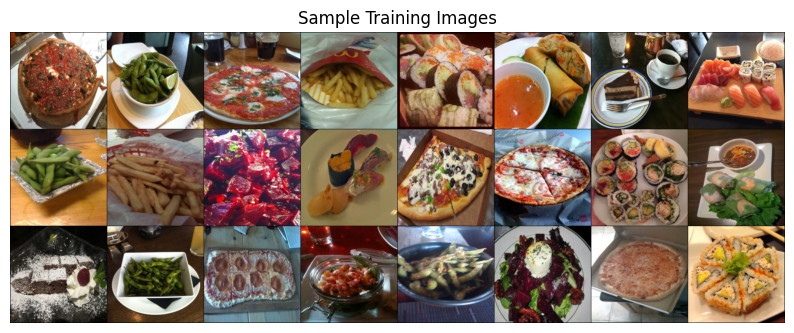

In [11]:
plot_sample_imgs(food_inputs[0:24,:,:,:])

In [12]:
Z_food = get_features(
    densenet, food_inputs, 
)

In [13]:
Z_food.shape

(350, 1024)

In [14]:
from sklearn.cluster import KMeans

k = 5
km = KMeans(n_clusters=k, n_init='auto', random_state=123)
km.fit(Z_food)

,"n_clusters n_clusters: int, default=8The number of clusters to form as well as the number ofcentroids to generate.For an example of how to choose an optimal value for `n_clusters` refer to:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_silhouette_analysis.py`.",5
,"init init: {'k-means++', 'random'}, callable or array-like of shape (n_clusters, n_features), default='k-means++'Method for initialization:* 'k-means++' : selects initial cluster centroids using sampling based on an empirical probability distribution of the points' contribution to the overall inertia. This technique speeds up convergence. The algorithm implemented is ""greedy k-means++"". It differs from the vanilla k-means++ by making several trials at each sampling step and choosing the best centroid among them.* 'random': choose `n_clusters` observations (rows) at random from data for the initial centroids.* If an array is passed, it should be of shape (n_clusters, n_features) and gives the initial centers.* If a callable is passed, it should take arguments X, n_clusters and a random state and return an initialization.For an example of how to use the different `init` strategies, see:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_digits.py`.For an evaluation of the impact of initialization, see the example:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_stability_low_dim_dense.py`.",'k-means++'
,"n_init n_init: 'auto' or int, default='auto'Number of times the k-means algorithm is run with different centroidseeds. The final results is the best output of `n_init` consecutive runsin terms of inertia. Several runs are recommended for sparsehigh-dimensional problems (see :ref:`kmeans_sparse_high_dim`).When `n_init='auto'`, the number of runs depends on the value of init:10 if using `init='random'` or `init` is a callable;1 if using `init='k-means++'` or `init` is an array-like... versionadded:: 1.2 Added 'auto' option for `n_init`... versionchanged:: 1.4 Default value for `n_init` changed to `'auto'`.",'auto'
,"max_iter max_iter: int, default=300Maximum number of iterations of the k-means algorithm for asingle run.",300
,"tol tol: float, default=1e-4Relative tolerance with regards to Frobenius norm of the differencein the cluster centers of two consecutive iterations to declareconvergence.",0.0001
,"verbose verbose: int, default=0Verbosity mode.",0
,"random_state random_state: int, RandomState instance or None, default=NoneDetermines random number generation for centroid initialization. Usean int to make the randomness deterministic.See :term:`Glossary `.",123
,"copy_x copy_x: bool, default=TrueWhen pre-computing distances it is more numerically accurate to centerthe data first. If copy_x is True (default), then the original data isnot modified. If False, the original data is modified, and put backbefore the function returns, but small numerical differences may beintroduced by subtracting and then adding the data mean. Note that ifthe original data is not C-contiguous, a copy will be made even ifcopy_x is False. If the original data is sparse, but not in CSR format,a copy will be made even if copy_x is False.",True
,"algorithm algorithm: {""lloyd"", ""elkan""}, default=""lloyd""K-means algorithm to use. The classical EM-style algorithm is `""lloyd""`.The `""elkan""` variation can be more efficient on some datasets withwell-defined clusters, by using the triangle inequality. However it'smore memory intensive due to the allocation of an extra array of shape`(n_samples, n_clusters)`... versionchanged:: 0.18 Added Elkan algorithm.. versionchanged:: 1.1 Renamed ""full"" to ""lloyd"", and deprecated ""auto"" and ""full"". Changed ""auto"" to use ""lloyd"" instead of ""elkan"".",'lloyd'


In [15]:
km.cluster_centers_.shape

(5, 1024)

244
Image indices:  [244 249 214 273 171 327]


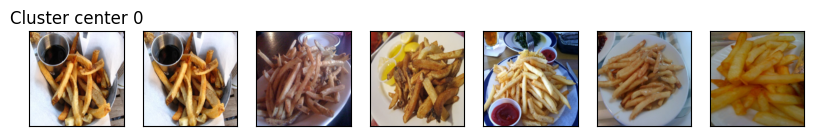

48
Image indices:  [ 48 191 265 334 343 138]


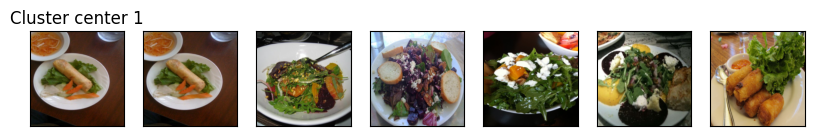

76
Image indices:  [ 76 138 313  61 190  48]


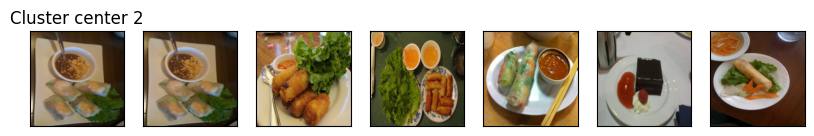

274
Image indices:  [274 203  89 330 209 205]


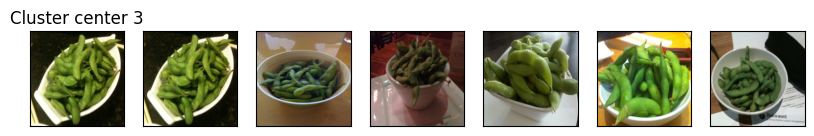

124
Image indices:  [124  27  25 253 280 223]


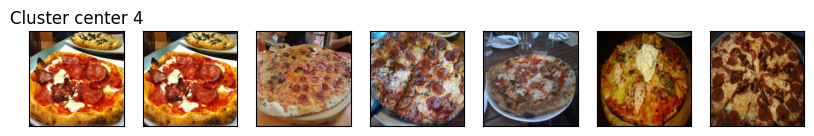

In [16]:
for cluster in range(k):
    get_cluster_images(km, Z_food, X_food, cluster, n_img=6)

<br><br>

## DBSCAN

In [17]:
dbscan = DBSCAN()

labels = dbscan.fit_predict(Z_food)
print("Unique labels: {}".format(np.unique(labels)))

Unique labels: [-1]


It identified all points as noise points. Let's explore the distances between points. 

In [18]:
from sklearn.metrics.pairwise import euclidean_distances

dists = euclidean_distances(Z_food)
np.fill_diagonal(dists, np.inf)
dists_df = pd.DataFrame(dists)
dists_df

,0,1,2,3,4,5,6,7,8,9,...,340,341,342,343,344,345,346,347,348,349
0,inf,27.170071,23.031963,29.344770,27.464485,25.905249,28.601198,27.226372,27.482910,27.221529,...,27.895405,28.627741,28.157877,24.296236,27.864172,26.458878,28.636688,23.513239,26.565344,27.202259
1,27.170071,inf,22.623034,24.378841,25.491880,21.179726,25.291134,22.400309,17.118837,23.523659,...,22.605665,19.422024,22.297949,20.873529,24.695156,23.107458,21.258495,19.471357,20.257633,22.101439
2,23.031963,22.623034,inf,28.764126,25.544821,23.159750,26.158792,23.423162,23.352556,25.552364,...,26.763525,25.627256,27.411240,22.771511,24.695322,25.684532,26.029633,20.417009,21.786682,22.903080
3,29.344770,24.378841,28.764126,inf,28.520521,23.345842,28.131287,27.448315,24.425112,19.679516,...,22.209080,26.940435,26.980894,25.166636,27.609039,21.547804,26.480219,24.750483,25.170492,26.520855
4,27.464485,25.491880,25.544821,28.520521,inf,21.172096,26.477964,23.458084,24.881807,26.123215,...,26.482233,24.862646,26.194010,22.634830,26.464815,25.304211,25.343542,23.945749,23.584101,25.460316
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
345,26.458878,23.107458,25.684532,21.547804,25.304211,22.533875,26.831314,24.927708,22.792894,21.153376,...,20.873131,24.183716,25.783266,23.444523,25.757410,inf,24.095850,22.627153,24.188885,24.653475
346,28.636688,21.258495,26.029633,26.480219,25.343542,21.611742,26.205795,25.979351,20.662205,23.817640,...,22.648527,21.091988,21.743132,23.498381,27.345236,24.095850,inf,22.860329,24.492994,25.513124
347,23.513239,19.471357,20.417009,24.750483,23.945749,19.392572,23.914518,22.881351,20.868397,23.173370,...,23.511862,23.249804,23.443993,17.126707,22.055302,22.627153,22.860329,inf,18.786024,18.716599
348,26.565344,20.257633,21.786682,25.170492,23.584101,19.035461,22.507225,21.890001,18.954798,24.086985,...,24.703289,22.101406,23.019146,18.728836,22.244556,24.188885,24.492994,18.786024,inf,22.293304


In [19]:
dists.min(), np.nanmax(dists[dists != np.inf]), np.mean(dists[dists != np.inf])

(np.float32(10.06717), np.float32(36.652683), np.float32(24.538565))

In [20]:
for eps in range(13, 20):
    print("\neps={}".format(eps))
    dbscan = DBSCAN(eps=eps, min_samples=3)
    labels = dbscan.fit_predict(Z_food)
    print("Number of clusters: {}".format(len(np.unique(labels))))
    print("Cluster sizes: {}".format(np.bincount(labels + 1)))


eps=13
Number of clusters: 2
Cluster sizes: [347   3]

eps=14
Number of clusters: 5
Cluster sizes: [334   3   6   4   3]

eps=15
Number of clusters: 4
Cluster sizes: [299  26   8  17]

eps=16
Number of clusters: 4
Cluster sizes: [248  86   3  13]

eps=17
Number of clusters: 2
Cluster sizes: [205 145]

eps=18
Number of clusters: 2
Cluster sizes: [160 190]

eps=19
Number of clusters: 2
Cluster sizes: [116 234]


In [21]:
dbscan = DBSCAN(eps=14, min_samples=3)
dbscan_labels = dbscan.fit_predict(Z_food)
print("Number of clusters: {}".format(len(np.unique(dbscan_labels))))
print("Cluster sizes: {}".format(np.bincount(dbscan_labels + 1)))
print("Unique labels: {}".format(np.unique(dbscan_labels)))

Number of clusters: 5
Cluster sizes: [334   3   6   4   3]
Unique labels: [-1  0  1  2  3]


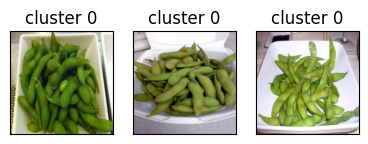

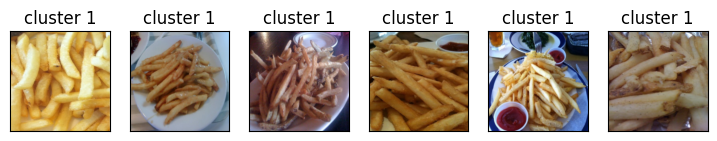

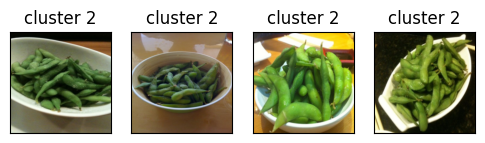

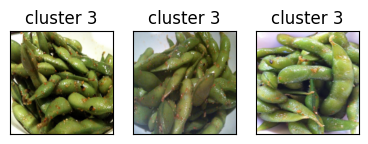

In [22]:
print_dbscan_clusters(Z_food, food_inputs, dbscan_labels)

Let's examine noise points identified by DBSCAN. 

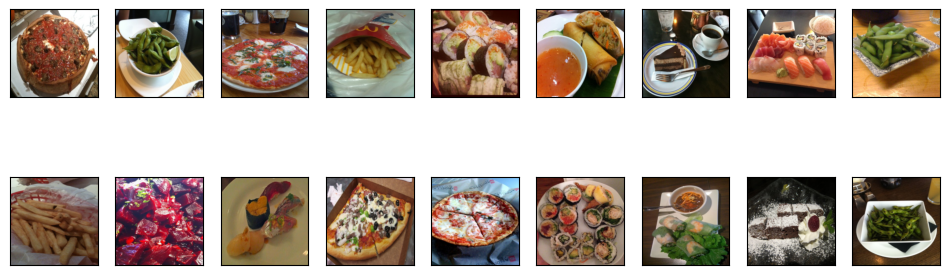

In [23]:
print_dbscan_noise_images(Z_food, food_inputs, dbscan_labels)

<br><br>

### Hierarchical clustering

In [24]:
set_seed(seed=42)

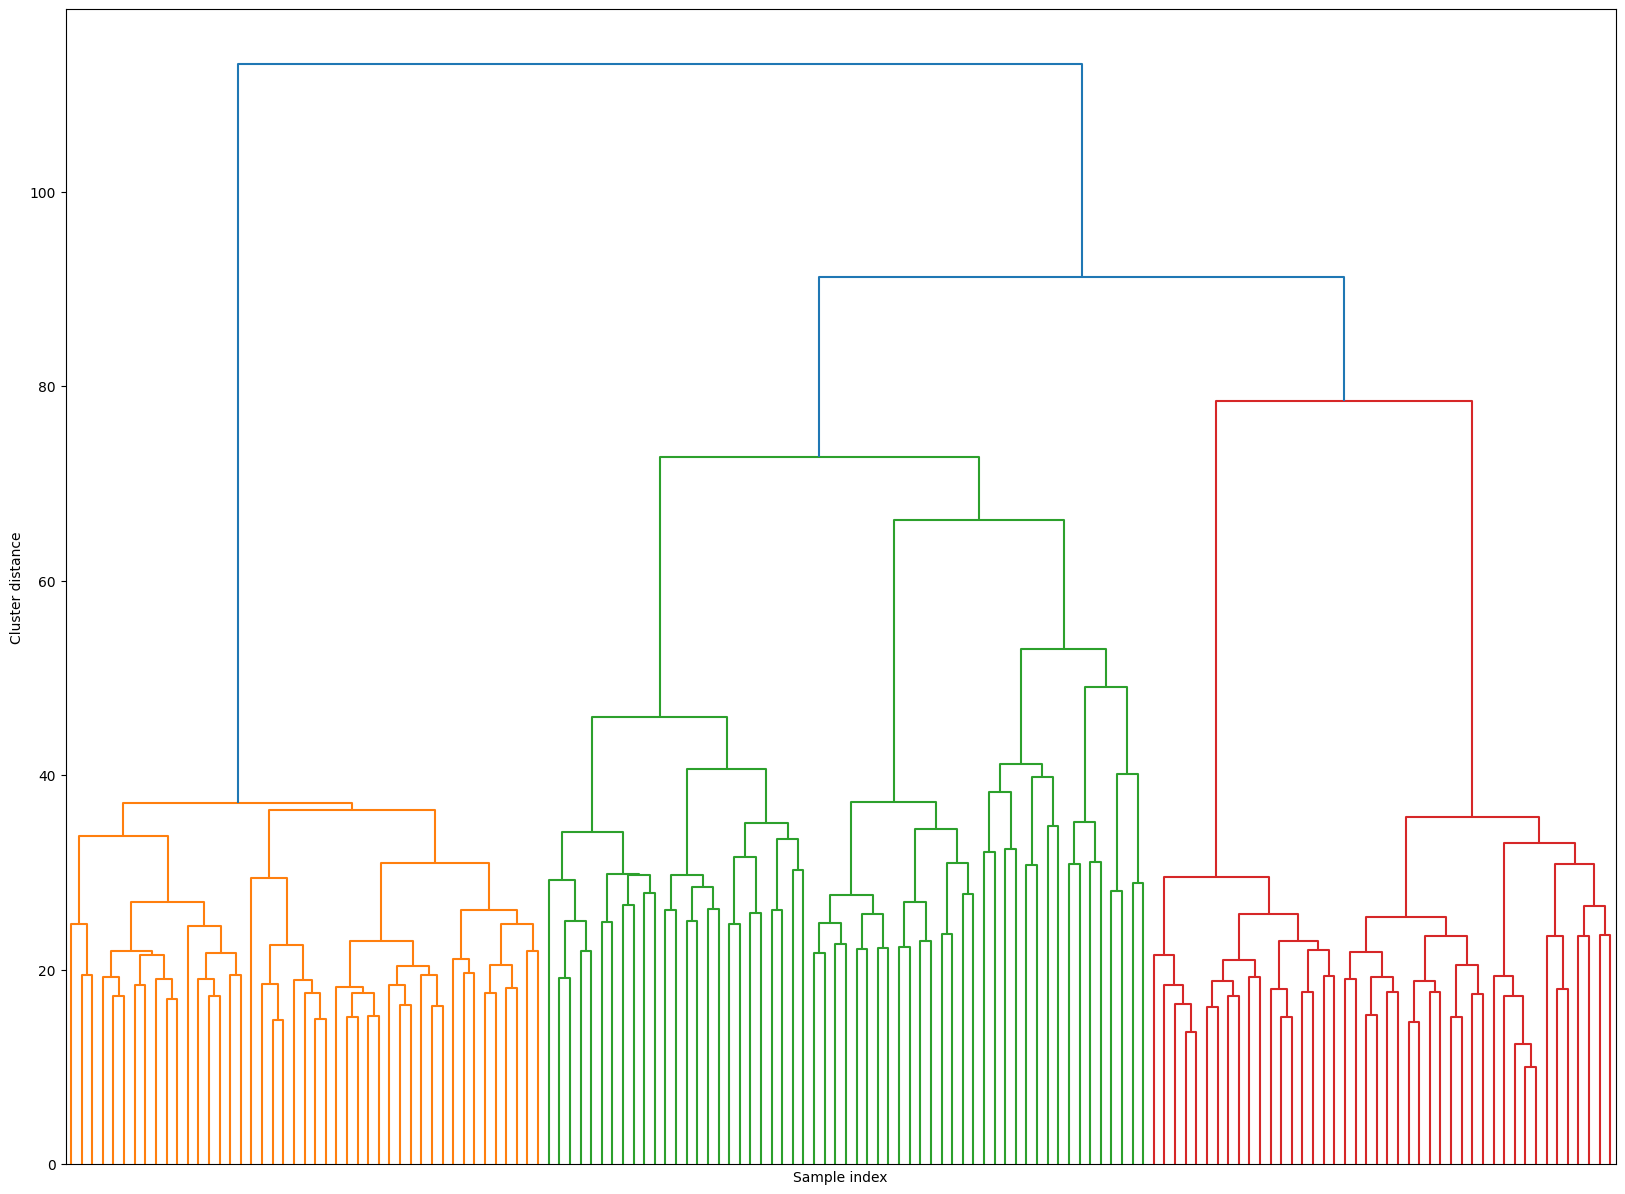

In [25]:
plt.figure(figsize=(20, 15))
Z_hrch = ward(Z_food)
dendrogram(Z_hrch, p=7, truncate_mode="level", no_labels=True)
plt.xlabel("Sample index")
plt.ylabel("Cluster distance");

In [26]:
cluster_labels = fcluster(Z_hrch, 20, criterion="maxclust")  # let's get flat clusters

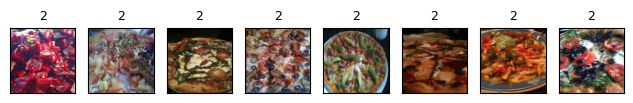

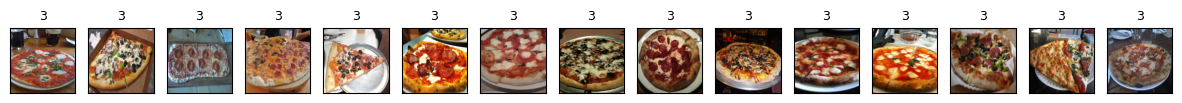

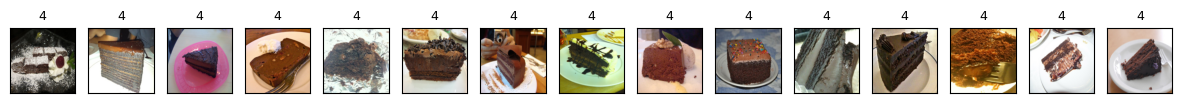

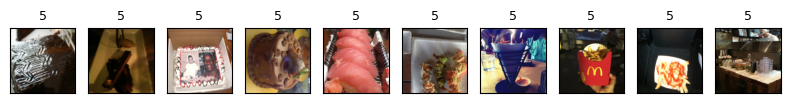

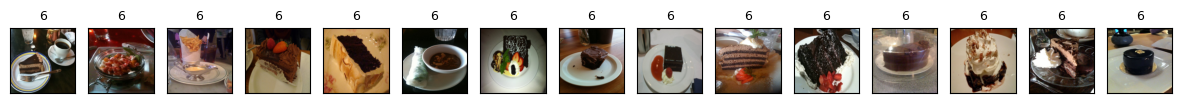

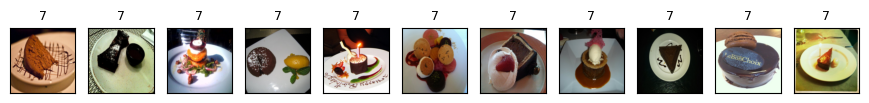

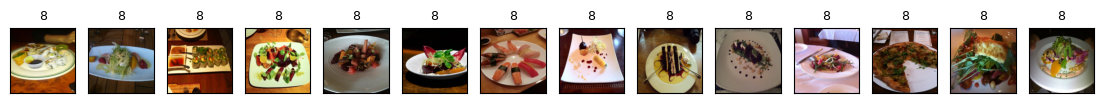

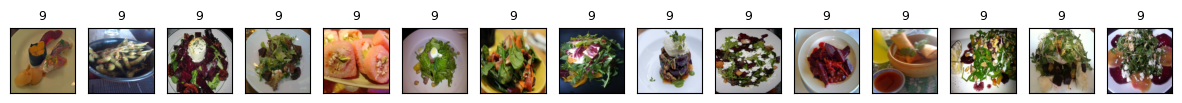

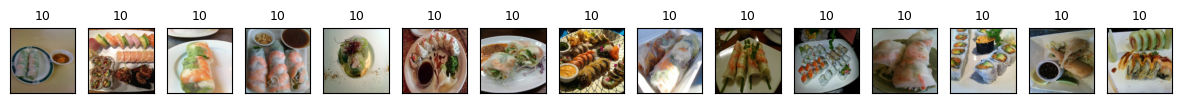

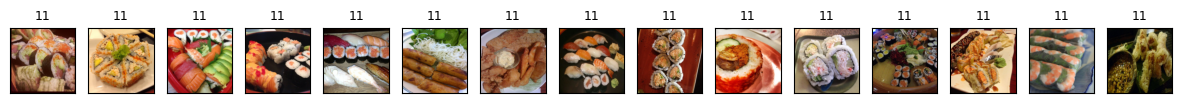

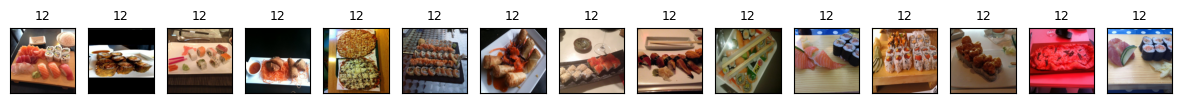

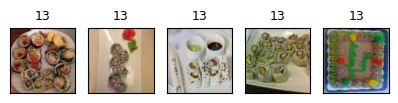

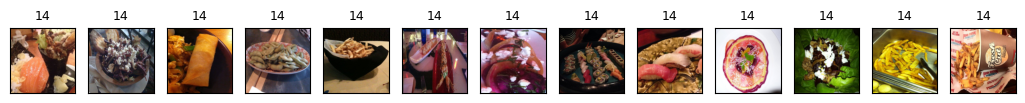

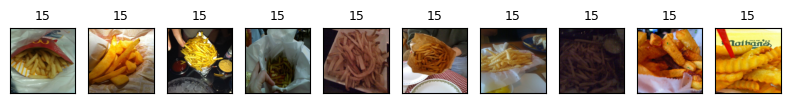

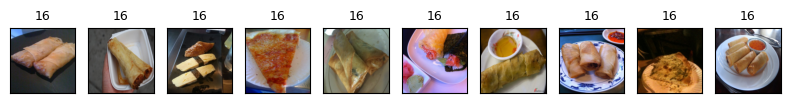

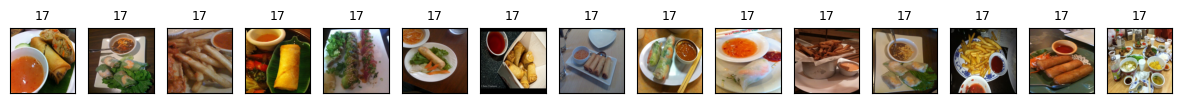

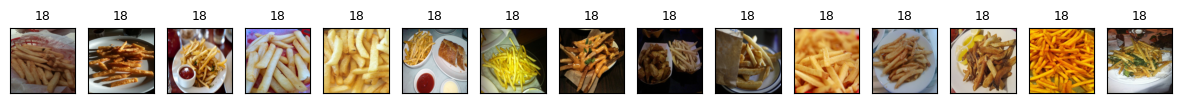

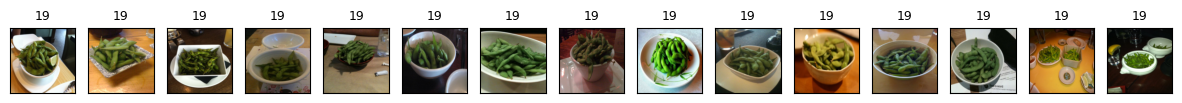

In [27]:
hand_picked_clusters = np.arange(2, 20)
#hand_picked_clusters = [2, 3, 5, 6,7, 8, 9, 10, 12, 14,15,16,17,19,20, 21,22, 24, 26, 27, 28]
print_hierarchical_clusters(
    food_inputs, Z_food, cluster_labels, hand_picked_clusters
)

- Some clusters correspond to people with distinct faces, age, facial expressions, hair colour and hair style, lighting and skin tone. 